# Estabilidade do riser com choke: lei de válvula, partida do estacionário, paragem adaptativa, modos da curva e o mapa

O caso de referência da intermitência severa passa a ser um poço: IPR linear na entrada da linha e choke no topo
do riser. A pergunta é onde, num plano abertura do choke × pressão do reservatório, o escoamento é permanente,
cicla com a saída suave ou dá golfada severa, e porquê. Pelo caminho, quatro alterações ao simulador que o mapa
exigiu e um estudo que descartou uma hipótese.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [039](../../docs/issues/039-lei-de-valvula-homogenea.md) lei de válvula homogénea
- [040](../../docs/issues/040-partida-do-estacionario.md) partida a partir do estado estacionário
- [041](../../docs/issues/041-paragem-adaptativa.md) tempo simulado adaptativo
- [042](../../docs/issues/042-modos-locais-da-curva.md) modos locais instáveis na curva
- [043](../../docs/issues/043-mapa-de-intermitencia-severa.md) o mapa

*Nenhuma simulação corre aqui. As 252 corridas do mapa vêm de `tools/slug_map.py build` e de
`mfsim batch runs/maps/well/<partida>/batch.json --jobs 12`; `tools/slug_map.py export` grava em
`notebooks/data` o resumo de todas (`severe_slug_map_well.npz`) e cinco corridas completas. O notebook só lê e
desenha.*

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

warnings.filterwarnings("ignore")
from mfsim.analysis import cycle_class, jansen_choke_dp_crit, jansen_choke_opening
from mfsim.fluid import Fluid
from mfsim.network.elements import valve_upstream_pressure
from mfsim.plotting import CYCLE_COLORS, CYCLE_LABELS, cycle_map
from mfsim.runs import find_run, load_run

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
SERIES = {"steady": "#2a78d6", "blocked": "#eb6834"}  # partida do estacionário, partida bloqueada
START_LABEL = {"steady": "partida do estacionário", "blocked": "partida bloqueada"}

with np.load(find_run("severe_slug_map_well")) as z:
    meta = json.loads(str(z["meta"]))
    cols = {k: z[k] for k in z.files if k != "meta"}
rows = [{k: (v[i].item() if hasattr(v[i], "item") else v[i]) for k, v in cols.items()} for i in range(cols["ab"].size)]
for r in rows:
    r["success"] = True
openings = sorted({r["ab"] for r in rows})
pressures = sorted({r["P_res"] for r in rows})
G = {(r["start"], r["P_res"], r["ab"]): r for r in rows}
print(f"{len(rows)} corridas: {len(openings)} aberturas × {len(pressures)} pressões × 2 partidas")
print("caso base:", meta["base_case"], "| paragem:", meta["settle"], "| tf máximo:", meta["tf"], "s")


def run_of(start, ab, P):
    return load_run(find_run(f"severe_slug_map_well_{start}_ab{ab:.3f}_P{P:04.1f}"))


def zones(model):
    """Índices dos nós do esquema: primeiro nó da linha a −3°, célula do ponto baixo (a última da linha),
    início do arco e base do riser."""
    th = np.rad2deg(model.pipes[0].scheme.theta_nodes)
    k_line = int(np.argmax(th < -2.0))
    k_arc = k_line + int(np.argmax(th[k_line:] > -2.0))
    k_base = int(np.argmax(th > 80.0))
    return dict(th=th, k_line=k_line, k_low=k_arc - 1, k_arc=k_arc, k_base=k_base)

252 corridas: 14 aberturas × 9 pressões × 2 partidas
caso base: cases/severe_slug/well_choke.json | paragem: {'window': 2000.0, 't_min': 2000.0, 'amp_tol': 0.1, 'rel_tol': 0.1} | tf máximo: 8000.0 s


## 039 · A lei de válvula decide se o choke estabiliza

A válvula da tese pondera as densidades das fases pela **vazão mássica**; como o gás quase não tem massa, a
densidade da mistura fica perto da do líquido mesmo com o gás a dominar o volume, e o choke quase não resiste ao
gás. A lei homogénea usa a densidade sem escorregamento, ponderada por **volume**, que é o mínimo físico para um
choke bifásico. Em líquido puro as duas coincidem.

 fração mássica de gás  densidade, tese  homogénea  queda homogénea ÷ tese
                 0.002           898 kg/m³     644 kg/m³                     1.4
                 0.010           891 kg/m³     301 kg/m³                     3.0
                 0.030           873 kg/m³     129 kg/m³                     6.9
                 0.100           810 kg/m³      43 kg/m³                    19.1


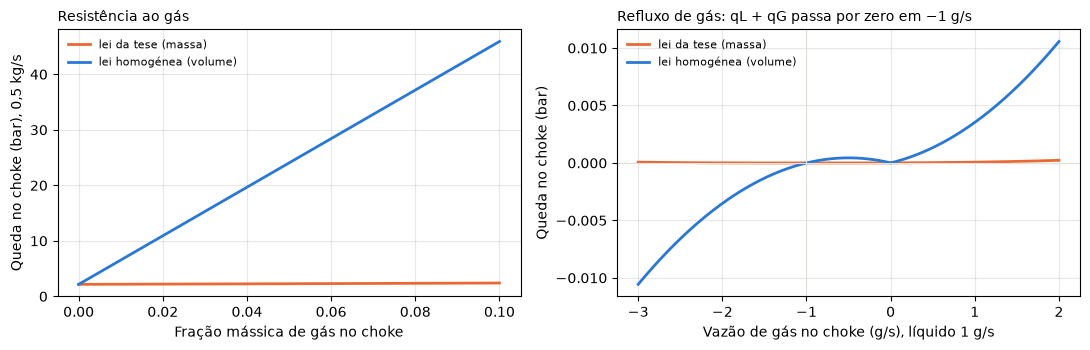

In [2]:
fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
PR, P_DOWN, CV, AB = 1e6, 4e5 / 1e6, 15.0, 0.1


def dp(qL, qG, law):
    return float(valve_upstream_pressure(P_DOWN, qL, qG, AB, CV, fluid, PR, law=law)[1])


rhoL, rhoG = fluid.rhoL0, float(fluid.rhoG(4e5))
print(f"{'fração mássica de gás':>22s} {'densidade, tese':>16s} {'homogénea':>10s} {'queda homogénea ÷ tese':>23s}")
for x in (0.002, 0.01, 0.03, 0.1):
    rt = (1 - x) * rhoL + x * rhoG
    rh = 1 / (x / rhoG + (1 - x) / rhoL)
    print(
        f"{x:22.3f} {rt:13.0f} kg/m³ {rh:7.0f} kg/m³ {dp(0.5 * (1 - x), 0.5 * x, 'homogeneous') / dp(0.5 * (1 - x), 0.5 * x, 'thesis'):23.1f}"
    )

xs = np.linspace(0.0, 0.1, 101)
qG_rev = np.linspace(-3e-3, 2e-3, 501)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for law, c, lab in (
    ("thesis", SERIES["blocked"], "lei da tese (massa)"),
    ("homogeneous", SERIES["steady"], "lei homogénea (volume)"),
):
    a1.plot(xs, [dp(0.5 * (1 - x), 0.5 * x, law) for x in xs], color=c, lw=2, label=lab)
    a2.plot(qG_rev * 1e3, [dp(1e-3, g, law) for g in qG_rev], color=c, lw=2, label=lab)
a1.set_xlabel("Fração mássica de gás no choke")
a1.set_ylabel("Queda no choke (bar), 0,5 kg/s")
a1.set_title("Resistência ao gás", loc="left", fontsize=10)
a2.axhline(0, color=GRID, lw=0.8)
a2.axvline(-1.0, color=GRID, lw=0.8)
a2.set_xlabel("Vazão de gás no choke (g/s), líquido 1 g/s")
a2.set_ylabel("Queda no choke (bar)")
a2.set_title("Refluxo de gás: qL + qG passa por zero em −1 g/s", loc="left", fontsize=10)
for a in (a1, a2):
    a.grid(alpha=0.3)
    a.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

No refluxo (à direita) a densidade da tese troca de sinal com a vazão total e a queda fica com o sinal errado:
foi o que fez falhar o integrador em 7 das 126 corridas do primeiro mapa. A lei homogénea não tem divisão pela
vazão total e tem sempre o sinal dela.

## 043 · O mapa

14 aberturas × 9 pressões do reservatório, duas partidas por ponto. **Partida do estacionário**: o estado
estacionário de cada ponto, obtido por continuação de Newton pela grelha e gravado como condição inicial exata,
perturbado em 0,1 % nas pressões. **Partida bloqueada**: linha cheia e riser bloqueado, como depois de uma
paragem. Estável: amplitude da pressão de entrada menor do que 0,1 bar ou 1 % da média, ou sem ciclo até aos
8000 s; golfada severa: pico da vazão de saída de pelo menos 2× a média; ciclo de pressão com saída suave no
resto. Cada célula mostra a pressão de entrada (estável) ou a pressão máxima e o período (com ciclo). A linha
tracejada é o critério de choke de Jansen, Shoham e Taitel (1996).

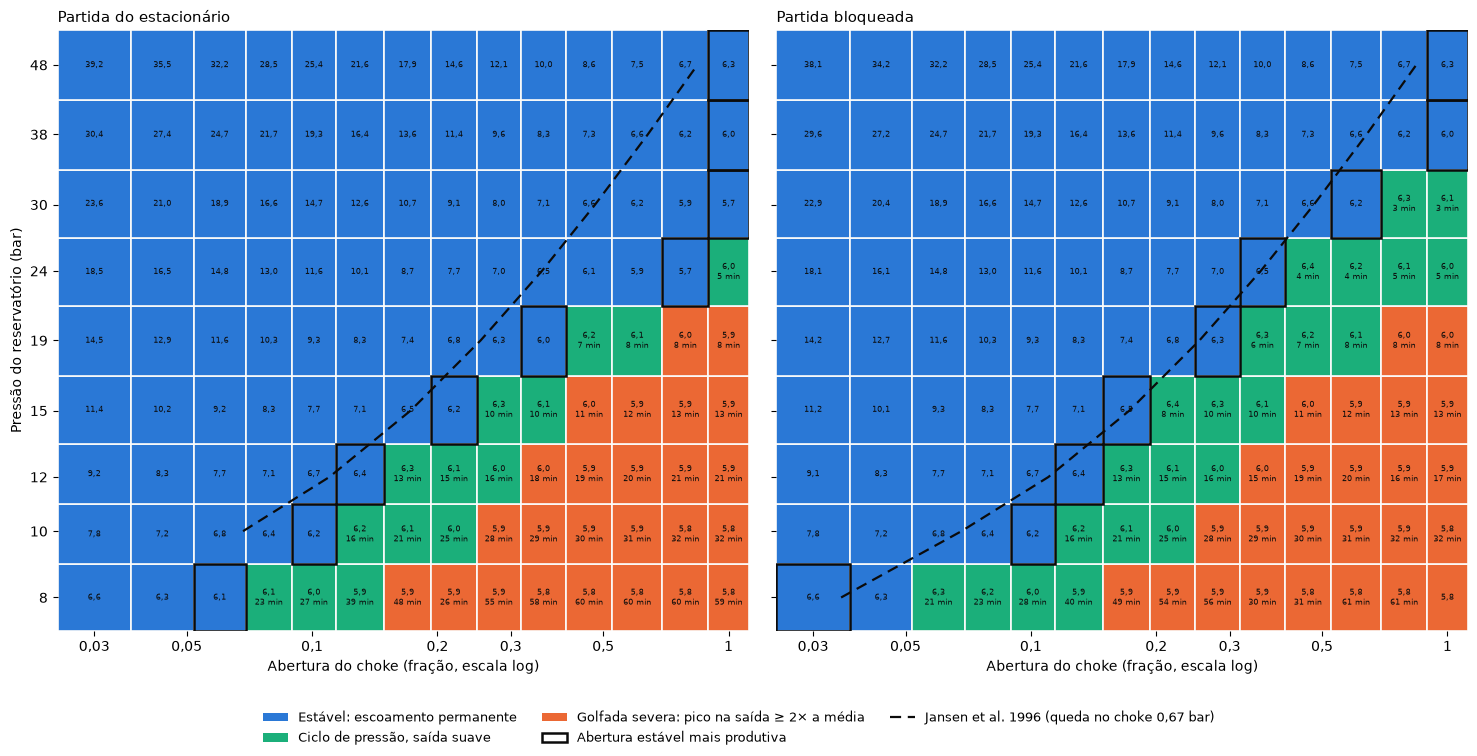

                              estáveis  ciclo  golfada
partida do estacionário             87     14       25
partida bloqueada                   79     22       25
critério de Jansen: queda crítica no choke 0.61–0.72 bar (eqs. 10 e 5)


In [3]:
dpc = 0.5 * (jansen_choke_dp_crit(Phi=0.87) + jansen_choke_dp_crit())
fig, axes = plt.subplots(1, 2, figsize=(15, 7.6), sharey=True)
for ax, start in zip(axes, ("steady", "blocked")):
    sub = [r for r in rows if r["start"] == start]
    xe, ye = cycle_map(ax, sub)
    jx, jy = [], []
    for P in pressures:
        a_c = jansen_choke_opening(
            [r["ab"] for r in sub if r["P_res"] == P], [r["q_mean"] for r in sub if r["P_res"] == P], dpc, CV=15.0
        )
        if a_c is not None:
            jx.append(a_c)
            jy.append(P)
    ax.plot(jx, jy, color=INK, lw=1.6, ls=(0, (5, 3)), zorder=6)
    ticks = [t for t in (0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0) if xe[0] <= t <= xe[-1]]
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}".replace(".", ",") for t in ticks])
    ax.set_xlim(xe[0], xe[-1])
    ax.set_xlabel("Abertura do choke (fração, escala log)")
    ax.set_title(START_LABEL[start].capitalize(), loc="left", fontsize=11)
axes[0].set_ylabel("Pressão do reservatório (bar)")
handles = [Patch(fc=CYCLE_COLORS[k], label=CYCLE_LABELS[k]) for k in ("stable", "cycling", "slugging")]
handles += [
    Patch(fc="none", ec=INK, lw=1.8, label="Abertura estável mais produtiva"),
    Line2D(
        [],
        [],
        color=INK,
        lw=1.6,
        ls=(0, (5, 3)),
        label="Jansen et al. 1996 (queda no choke " + f"{dpc:.2f}".replace(".", ",") + " bar)",
    ),
]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, fontsize=9)
fig.subplots_adjust(left=0.05, right=0.99, top=0.95, bottom=0.16, wspace=0.04)
plt.show()

print(f"{'':28s} {'estáveis':>9s} {'ciclo':>6s} {'golfada':>8s}")
for start in ("steady", "blocked"):
    c = [r["cls"] for r in rows if r["start"] == start]
    print(f"{START_LABEL[start]:28s} {c.count('stable'):9d} {c.count('cycling'):6d} {c.count('slugging'):8d}")
print(
    f"critério de Jansen: queda crítica no choke {jansen_choke_dp_crit(Phi=0.87):.2f}–{jansen_choke_dp_crit():.2f} bar (eqs. 10 e 5)"
)

### Histerese

As células em que as duas partidas dão classes diferentes. Todas são estáveis a partir do estacionário e ciclam
a partir da partida bloqueada: logo acima da fronteira, entre 15 e 30 bar, o poço que já escoa estável aguenta o
choke mais aberto do que o poço a arrancar de uma paragem.

In [4]:
diff = [(P, ab) for P in pressures for ab in openings if G[("steady", P, ab)]["cls"] != G[("blocked", P, ab)]["cls"]]
print(f"{len(diff)} células com classes diferentes")
print(
    f"{'P_res (bar)':>11s} {'abertura':>9s} {'estacionário':>13s} {'bloqueada':>10s} {'amplitude bloqueada (bar)':>26s}"
)
for P, ab in diff:
    s, b = G[("steady", P, ab)], G[("blocked", P, ab)]
    print(f"{P:11.0f} {ab:9.3f} {s['cls']:>13s} {b['cls']:>10s} {b['amp']:26.2f}")

8 células com classes diferentes
P_res (bar)  abertura  estacionário  bloqueada  amplitude bloqueada (bar)
          8     0.060        stable    cycling                       0.24
         15     0.220        stable    cycling                       0.31
         19     0.360        stable    cycling                       0.61
         24     0.460        stable    cycling                       0.42
         24     0.600        stable    cycling                       0.79
         24     0.800        stable    cycling                       1.05
         30     0.800        stable    cycling                       0.73
         30     1.000        stable    cycling                       0.82


## Diagrama de bifurcação a 15 bar e o custo do choke

Para cada abertura: a faixa da pressão de entrada (mínimo e máximo) em cada partida, e o estacionário de partida
(que existe sempre, estável ou não). Em baixo, a produção média simulada e a do estacionário: a diferença entre a
abertura total e a abertura estável mais produtiva é o que um controlador anti-slug que segurasse o estacionário
instável poderia recuperar.

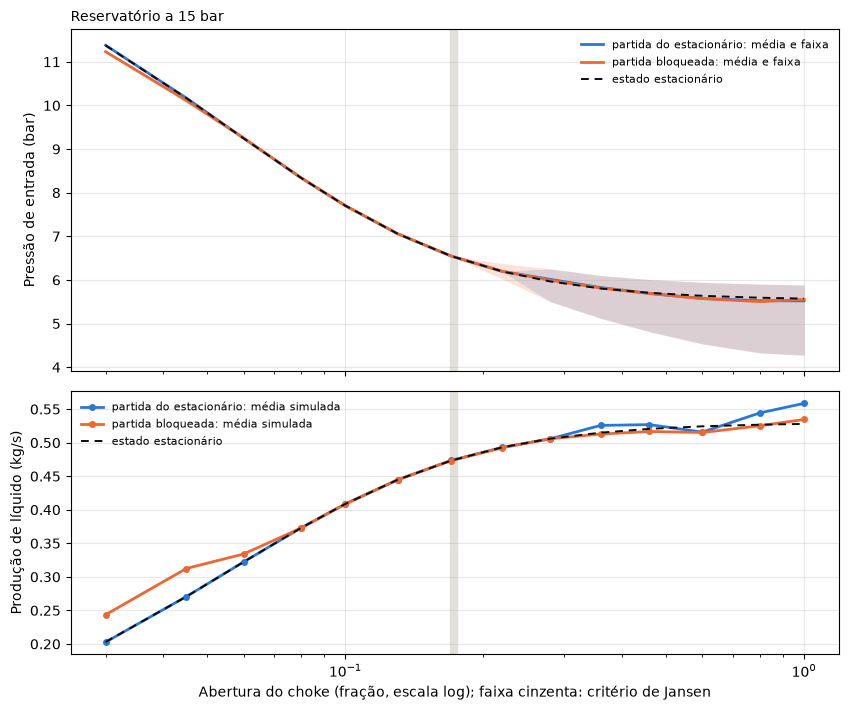

abertura estável mais produtiva: 0.22 -> 0.493 kg/s
abertura total: estacionário 0.528 kg/s, média simulada 0.559 kg/s (slugging)
ganho possível de segurar o estacionário instável: +7.1%


In [5]:
P_SEL = 15.0
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8.5, 7.2), sharex=True, gridspec_kw=dict(height_ratios=[1.3, 1]))
for start in ("steady", "blocked"):
    sub = sorted([G[(start, P_SEL, ab)] for ab in openings], key=lambda r: r["ab"])
    ab = np.array([r["ab"] for r in sub])
    a1.fill_between(ab, [r["P_min"] for r in sub], [r["P_max"] for r in sub], color=SERIES[start], alpha=0.18, lw=0)
    a1.plot(ab, [r["P_mean"] for r in sub], color=SERIES[start], lw=2, label=f"{START_LABEL[start]}: média e faixa")
    a2.plot(
        ab,
        [r["q_mean"] for r in sub],
        color=SERIES[start],
        lw=2,
        marker="o",
        ms=4,
        label=f"{START_LABEL[start]}: média simulada",
    )
st = sorted([G[("steady", P_SEL, ab)] for ab in openings], key=lambda r: r["ab"])
a1.plot([r["ab"] for r in st], [r["P_ss"] for r in st], color=INK, lw=1.4, ls=(0, (4, 3)), label="estado estacionário")
a2.plot([r["ab"] for r in st], [r["q_ss"] for r in st], color=INK, lw=1.4, ls=(0, (4, 3)), label="estado estacionário")
a_c = jansen_choke_opening([r["ab"] for r in st], [r["q_mean"] for r in st], dpc, CV=15.0)
for a in (a1, a2):
    a.axvline(a_c, color=GRID, lw=6, zorder=0)
    a.set_xscale("log")
    a.grid(alpha=0.3)
    a.legend(frameon=False, fontsize=8)
a1.set_ylabel("Pressão de entrada (bar)")
a2.set_ylabel("Produção de líquido (kg/s)")
a2.set_xlabel("Abertura do choke (fração, escala log); faixa cinzenta: critério de Jansen")
a1.set_title(f"Reservatório a {P_SEL:g} bar", loc="left", fontsize=10)
plt.tight_layout()
plt.show()

best = max((r for r in st if r["cls"] == "stable"), key=lambda r: r["q_mean"])
full = G[("steady", P_SEL, 1.0)]
print(f"abertura estável mais produtiva: {best['ab']:.2f} -> {best['q_mean']:.3f} kg/s")
print(f"abertura total: estacionário {full['q_ss']:.3f} kg/s, média simulada {full['q_mean']:.3f} kg/s ({full['cls']})")
print(f"ganho possível de segurar o estacionário instável: {full['q_ss'] / best['q_mean'] - 1:+.1%}")

## Abrir o choke a 15 bar: estável, ciclo de pressão e golfada severa

Três corridas da partida do estacionário, com o choke cada vez mais aberto. Em cima a pressão na entrada da linha,
em baixo a vazão de líquido à saída do riser.

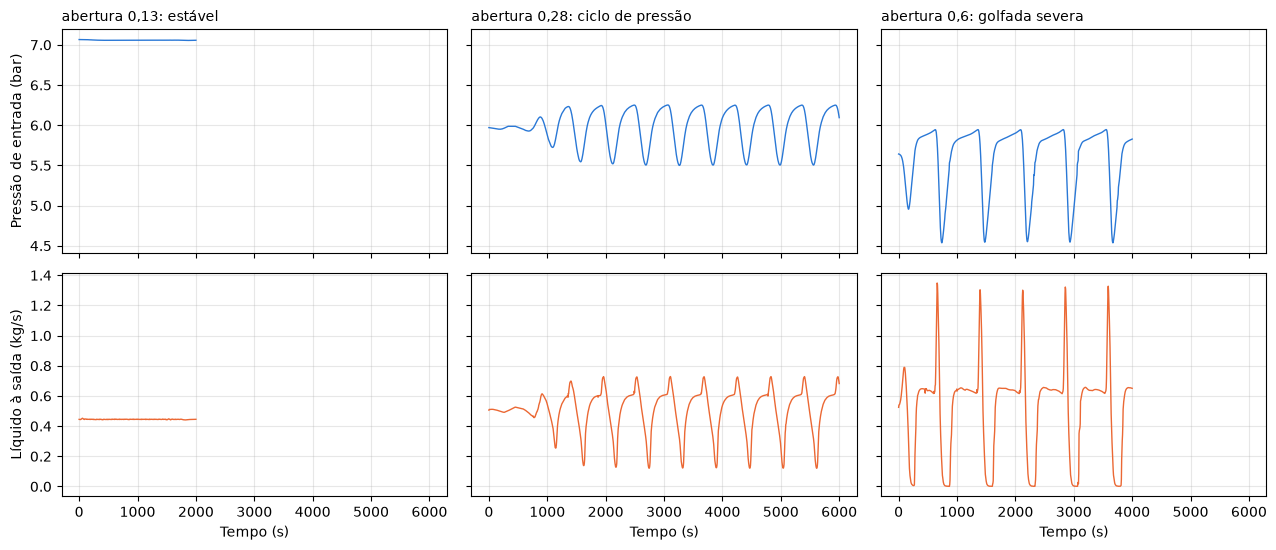

abertura 0.13: stable   P  7.05– 7.07 bar, período      --, saída média 0.445 kg/s, pico  1.0× a média, parou por 'steady' aos 2000
abertura 0.28: cycling  P  5.50– 6.25 bar, período   573 s, saída média 0.506 kg/s, pico  1.4× a média, parou por 'cycle' aos 6000
abertura 0.60: slugging P  4.54– 5.95 bar, período   733 s, saída média 0.516 kg/s, pico  2.6× a média, parou por 'cycle' aos 4000


In [6]:
sel = [(0.13, "estável"), (0.28, "ciclo de pressão"), (0.6, "golfada severa")]
runs = {ab: run_of("steady", ab, P_SEL) for ab, _ in sel}
fig, axes = plt.subplots(2, 3, figsize=(13, 5.6), sharex=True, sharey="row")
for j, (ab, lab) in enumerate(sel):
    r = runs[ab]
    p = r.pipe(0)["out"]
    axes[0, j].plot(r.T, p["P_bar"][1], color=SERIES["steady"], lw=1)
    axes[1, j].plot(r.T, p["qL"][-1], color=SERIES["blocked"], lw=1)
    axes[0, j].set_title(f"abertura {ab:g}: {lab}".replace(".", ","), loc="left", fontsize=10)
    axes[1, j].set_xlabel("Tempo (s)")
    for a in axes[:, j]:
        a.grid(alpha=0.3)
axes[0, 0].set_ylabel("Pressão de entrada (bar)")
axes[1, 0].set_ylabel("Líquido à saída (kg/s)")
plt.tight_layout()
plt.show()
for ab, lab in sel:
    r = G[("steady", P_SEL, ab)]
    per = f"{r['period']:.0f} s" if np.isfinite(r["period"]) else "--"
    print(
        f"abertura {ab:4.2f}: {r['cls']:8s} P {r['P_min']:5.2f}–{r['P_max']:5.2f} bar, período {per:>7s}, saída média {r['q_mean']:.3f} kg/s, pico {r['surge']:4.1f}× a média, parou por '{r['settle']}' aos {r['t_end']:.0f}"
    )

### A golfada no espaço e no tempo

Fração de gás nos últimos 80 m da linha, no arco e no riser, contra o tempo. No ciclo de pressão o riser
respira sem se encher de líquido; na golfada severa o líquido acumula-se no ponto baixo e sobe o riser até o
bloquear, a linha pressuriza e o gás expulsa o tampão (as faixas claras que atravessam o riser).

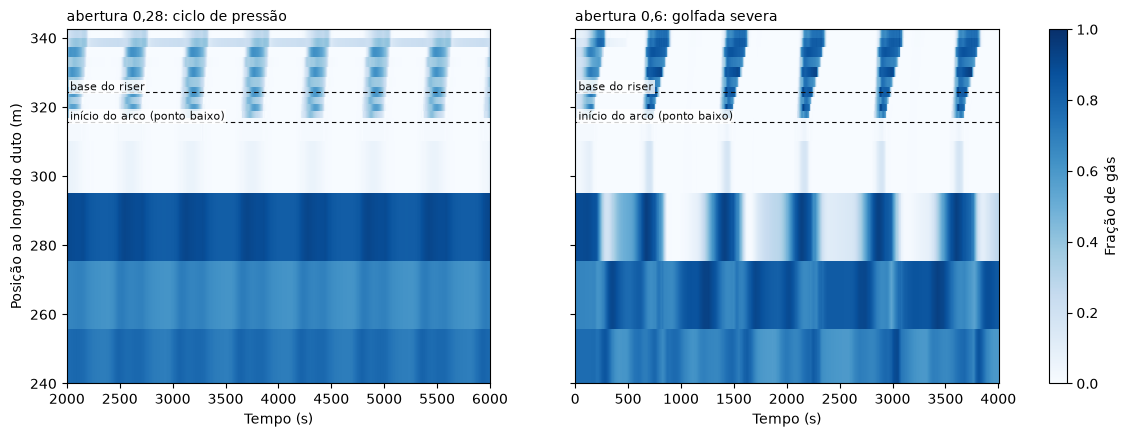

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, ab in zip(axes, (0.28, 0.6)):
    r = runs[ab]
    p = r.pipe(0)
    x = np.asarray(p["x"])
    t_win = r.T >= r.T[-1] - 4000
    im = ax.pcolormesh(
        r.T[t_win], x, p["out"]["alphaG"][:, t_win], cmap="Blues", vmin=0, vmax=1, shading="auto", rasterized=True
    )
    z = zones(r.model)
    for xv, lab in ((x[z["k_arc"]], "início do arco (ponto baixo)"), (x[z["k_base"]], "base do riser")):
        ax.axhline(xv, color=INK, lw=0.8, ls=(0, (4, 3)))
        ax.text(
            r.T[t_win][0] + 30, xv + 0.6, lab, fontsize=8, color=INK, bbox=dict(fc="white", ec="none", alpha=0.8, pad=1)
        )
    ax.set_ylim(240, x[-1])
    ax.set_xlabel("Tempo (s)")
    ax.set_title(f"abertura {ab:g}: {dict(sel)[ab]}".replace(".", ","), loc="left", fontsize=10)
axes[0].set_ylabel("Posição ao longo do duto (m)")
fig.colorbar(im, ax=axes, label="Fração de gás", fraction=0.025)
plt.show()

### A célula de histerese a 24 bar e abertura 0,6

O mesmo ponto nas duas partidas: a partir do estacionário o escoamento fica permanente; a partir da linha
bloqueada instala-se um ciclo de pressão que não desaparece.

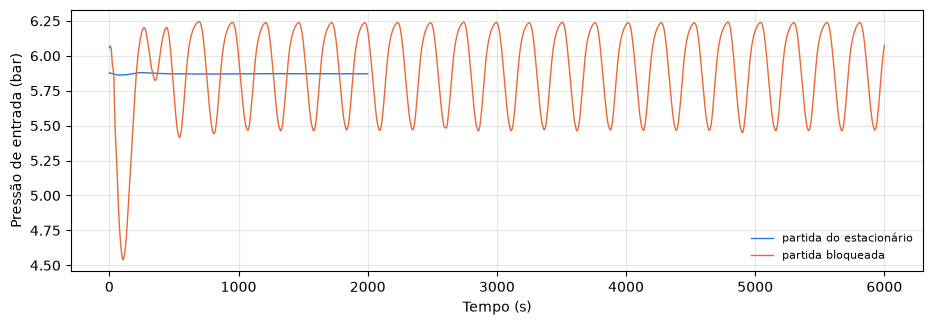

partida do estacionário : stable   amplitude 0.018 bar, parou por 'steady' aos 2000
partida bloqueada       : cycling  amplitude 0.792 bar, parou por 'cycle' aos 6000


In [8]:
fig, ax = plt.subplots(figsize=(11, 3.4))
for start in ("steady", "blocked"):
    r = run_of(start, 0.6, 24.0)
    ax.plot(r.T, r.pipe(0)["out"]["P_bar"][1], color=SERIES[start], lw=1, label=START_LABEL[start])
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Pressão de entrada (bar)")
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=8)
plt.show()
for start in ("steady", "blocked"):
    r = G[(start, 24.0, 0.6)]
    print(
        f"{START_LABEL[start]:24s}: {r['cls']:8s} amplitude {r['amp']:.3f} bar, parou por '{r['settle']}' aos {r['t_end']:.0f}"
    )

## 040 e 041 · Partida do estacionário e paragem adaptativa

Todas as partidas do estacionário convergiram no Newton (o estado gravado já era o estacionário). A paragem
adaptativa integra em janelas de 2000 s e para quando a amplitude fica abaixo da tolerância ou o ciclo se repete;
uma deriva sem ciclo segue até aos 8000 s e conta como estável.

Newton convergiu na partida do estacionário: 126 de 126
                          permanente  ciclo repetido  tempo máximo  passos (mediana)
partida do estacionário           84              18            24              9288
partida bloqueada                 76              23            27             12729


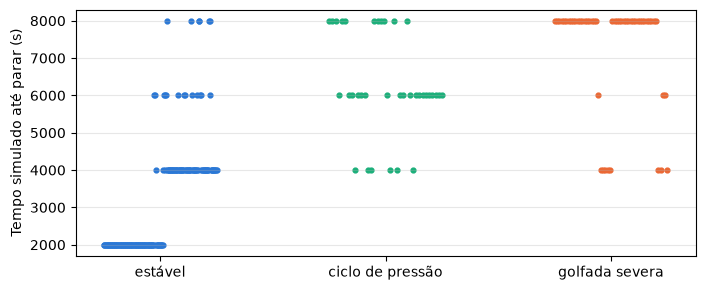

In [9]:
print(
    f"Newton convergiu na partida do estacionário: {sum(r['initial'] for r in rows if r['start'] == 'steady')} de {len(openings) * len(pressures)}"
)
print(f"{'':24s} {'permanente':>11s} {'ciclo repetido':>15s} {'tempo máximo':>13s} {'passos (mediana)':>17s}")
for start in ("steady", "blocked"):
    sub = [r for r in rows if r["start"] == start]
    s = [r["settle"] for r in sub]
    print(
        f"{START_LABEL[start]:24s} {s.count('steady'):11d} {s.count('cycle'):15d} {s.count('tf'):13d} {int(np.median([r['n_steps'] for r in sub])):17d}"
    )
fig, ax = plt.subplots(figsize=(8, 3.2))
for k, cls in enumerate(("stable", "cycling", "slugging")):
    t = [r["t_end"] for r in rows if r["cls"] == cls]
    ax.scatter(np.full(len(t), k) + np.linspace(-0.25, 0.25, len(t)), t, s=12, color=CYCLE_COLORS[cls])
ax.set_xticks([0, 1, 2])
ax.set_xticklabels(["estável", "ciclo de pressão", "golfada severa"])
ax.set_ylabel("Tempo simulado até parar (s)")
ax.grid(alpha=0.3, axis="y")
plt.show()

## 042 · Os autovalores do estacionário em três pontos: estável, ciclo de pressão e golfada severa

A 15 bar, as aberturas 0,13 (estável), 0,28 (ciclo de pressão) e 0,6 (golfada severa) têm todas um estado
estacionário, o ponto de partida gravado das corridas. Se a golfada fosse uma bifurcação de Hopf desse
estacionário, veríamos um par complexo lento a atravessar o eixo imaginário entre o primeiro e o terceiro ponto.
Em cima, o espetro inteiro; em baixo, a zona lenta perto da origem, onde esse par apareceria.

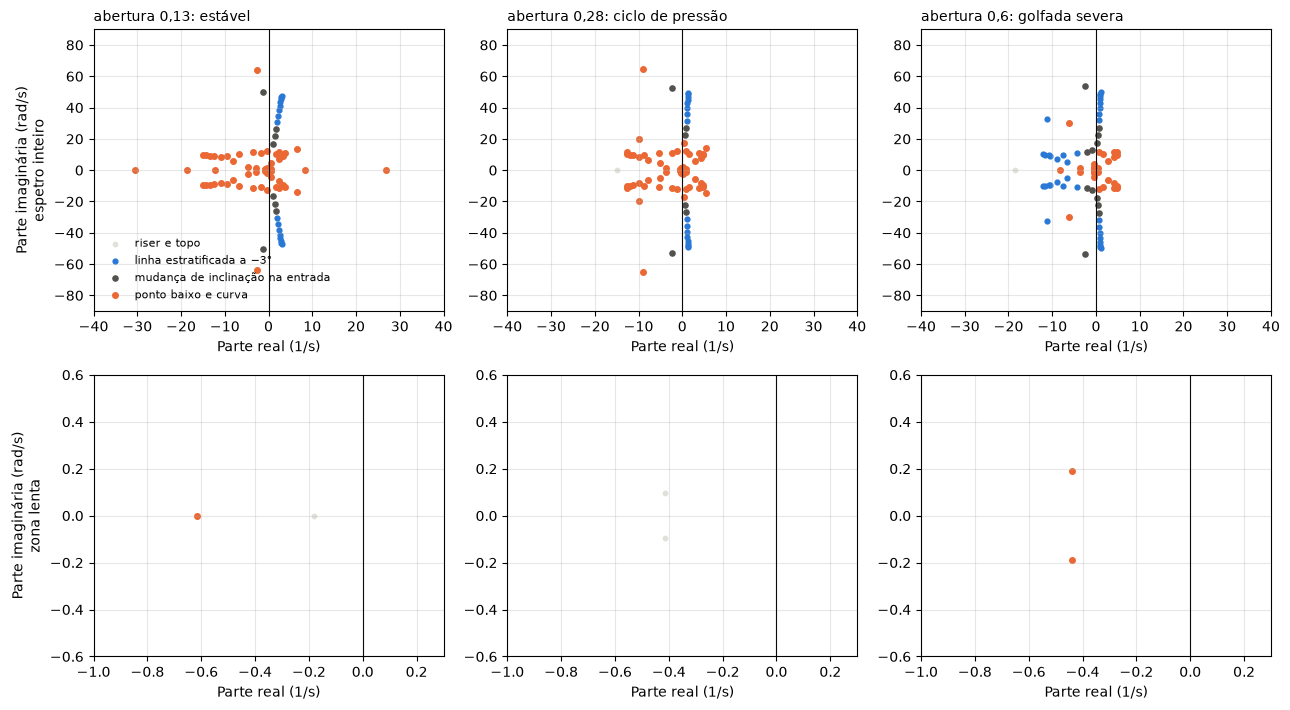

ponto                       resíduo  vel. complexas  instáveis  na curva  na linha  na entrada  maior (1/s)  lentos: maior parte real
0.13 (estável)                8e-12               0         42        20        16           6        26.91                    -0.181
0.28 (ciclo de pressão)       4e-10               0         44        24        16           4         5.49                    -0.414
0.6 (golfada severa)          7e-10               0         40        18        16           6         4.82                    -0.440

ponto estável, os quatro modos mais instáveis:
       autovalor (1/s)  célula  ângulo  fração de gás
   +26.91     +0.00j      18      9°          0.015
    +8.26     +0.00j      19     32°          0.102
    +6.53    +13.76j      19     32°          0.102
    +6.53    -13.76j      19     32°          0.102


In [10]:
from mfsim.compiled import get_jax


def spectrum(ab):
    """Autovalores da Jacobiana exata (JAX) no estacionário de partida do ponto (15 bar, ab), a célula onde cada
    vetor próprio tem mais peso e a zona dessa célula: "curva" (da célula do ponto baixo à base do riser),
    "entrada" (até ao primeiro nó da linha a −3°) ou "resto"."""
    r = run_of("steady", ab, P_SEL)
    m = r.model
    X = np.array(r.X[:, 0], float)
    X[m.state_slots() == 1] /= 1.0 + meta["perturb"]  # o estacionário antes da perturbação de partida
    _, jac = get_jax(m)
    w, V = np.linalg.eig(np.asarray(jac(0.0, X)))
    pb = m.pipes[0]
    z = zones(m)
    loc = np.array([pb.free[np.argmax(np.abs(V[:, i]))] // 4 for i in range(w.size)])
    where = np.select(
        [(loc >= z["k_low"]) & (loc <= z["k_base"]), loc <= z["k_line"], loc < z["k_low"]],
        ["curva", "entrada", "linha"],
        default="riser",
    )
    Y = m.assemble(0.0, X)[1][0]
    speeds = pb.model.eigenvalues(Y[: z["th"].size], z["th"])
    return dict(
        w=w,
        loc=loc,
        where=where,
        th=z["th"],
        Y=Y,
        res=float(np.linalg.norm(m.rhs(0.0, X))),
        complex_speeds=int(np.sum(np.abs(speeds.imag) > 1e-6)),
    )


ZONES = (
    ("riser", GRID, 10, "riser e topo"),
    ("linha", SERIES["steady"], 12, "linha estratificada a −3°"),
    ("entrada", "#52514e", 14, "mudança de inclinação na entrada"),
    ("curva", SERIES["blocked"], 16, "ponto baixo e curva"),
)
spec = {ab: spectrum(ab) for ab, _ in sel}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.2))
for j, (ab, lab) in enumerate(sel):
    d = spec[ab]
    for k, (xl, yl) in enumerate((((-40, 40), (-90, 90)), ((-1.0, 0.3), (-0.6, 0.6)))):
        ax = axes[k, j]
        for zone, c, sz, lab_z in ZONES:
            mk = d["where"] == zone
            ax.scatter(d["w"].real[mk], d["w"].imag[mk], s=sz, color=c, label=lab_z)
        ax.axvline(0, color=INK, lw=0.8)
        ax.set_xlim(*xl)
        ax.set_ylim(*yl)
        ax.grid(alpha=0.3)
        ax.set_xlabel("Parte real (1/s)")
    axes[0, j].set_title(f"abertura {ab:g}: {lab}".replace(".", ","), loc="left", fontsize=10)
axes[0, 0].set_ylabel("Parte imaginária (rad/s)\nespetro inteiro")
axes[1, 0].set_ylabel("Parte imaginária (rad/s)\nzona lenta")
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

print(
    f"{'ponto':26s} {'resíduo':>8s} {'vel. complexas':>15s} {'instáveis':>10s} {'na curva':>9s} {'na linha':>9s}"
    f" {'na entrada':>11s}"
    f" {'maior (1/s)':>12s} {'lentos: maior parte real':>25s}"
)
for ab, lab in sel:
    d = spec[ab]
    w = d["w"]
    unst = w.real > 1e-9
    slow = w[np.abs(w) < 0.5]
    print(
        f"{f'{ab:g} ({lab})':26s} {d['res']:8.0e} {d['complex_speeds']:15d} {int(unst.sum()):10d}"
        f" {int((unst & (d['where'] == 'curva')).sum()):9d} {int((unst & (d['where'] == 'linha')).sum()):9d}"
        f" {int((unst & (d['where'] == 'entrada')).sum()):11d}"
        f" {w.real.max():12.2f} {slow.real.max() if slow.size else float('nan'):+25.3f}"
    )
d = spec[0.13]
o = np.argsort(-d["w"].real)[:4]
print("\nponto estável, os quatro modos mais instáveis:")
print(f"{'autovalor (1/s)':>22s} {'célula':>7s} {'ângulo':>7s} {'fração de gás':>14s}")
for i in o:
    k = d["loc"][i]
    print(
        f"{d['w'][i].real:+9.2f} {d['w'][i].imag:+9.2f}j {k:7d} {d['th'][min(k, d['th'].size - 1)]:6.0f}° {d['Y'][k, 0]:14.3f}"
    )

Os três espetros têm o mesmo desenho. Há dezenas de modos rápidos instáveis, todos locais: os mais fortes no
ponto baixo da curva, onde a linha a −3° encontra o arco e o duto está quase cheio de líquido; outros fracos (até
3 /s) e de alta frequência (30 a 50 rad/s) na linha estratificada e na passagem do troço horizontal de entrada para
a linha. O riser não tem nenhum. A zona lenta só tem modos amortecidos. O ponto **estável** é o que tem o modo
mais instável. Nada no espetro separa o ponto estável da golfada severa; o que os separa é o destino não linear
da trajetória, que só a simulação dinâmica mostra.

Resultado dos testes da issue 042 (corridas fora deste notebook, guiões em `runs/maps/prototype/`):

| teste | resultado |
|---|---|
| deslocar ou alargar a regra de bolhas e a mistura por ângulo | o modo muda de célula, não desaparece |
| refinar a malha 2× | crescimento de 27 para 37 /s, 7× mais passos |
| refinar a malha 4× | a integração falha aos 821 s |
| limiar de bolhas a 10 % | crescimento 3,5 /s e 7× menos passos neste ponto; validação mista (Tengesdal melhora, Jansen piora) |

**Leitura.** Os autovalores do estacionário não desenham este mapa: passar a golfada é um efeito não linear, que
só a simulação dinâmica decide. Um mapa por bifurcação de Hopf exigiria primeiro um fechamento adequado para um
ponto baixo quase cheio de líquido, onde o padrão físico é disperso ou intermitente e não estratificado.

## Lições

- **A lei de válvula é parte do modelo de estabilidade.** Com a densidade ponderada por massa o choke não
  estabiliza nada; a fronteira só aparece, e coincide com o critério de Jansen, com a densidade por volume.
- **Um mapa de estabilidade precisa de duas partidas.** A partida bloqueada dá o pior caso, a do estacionário o
  comportamento de um poço já em produção; a diferença é a histerese.
- **O tempo de cada corrida deve ser o que ela precisa.** Com a paragem adaptativa, os estáveis param aos 2000 s
  e os lentos seguem até aos 8000 s.
- **Desconfiar de autovalores rápidos e locais.** Num modelo a dois fluidos discretizado, o estacionário pode ser
  linearmente instável por razões de malha e de fechamento que nada têm a ver com a golfada.